# 01 - Data Exploration: Diabetes Hospital Readmission

**Dataset:** UCI *Diabetes 130-US Hospitals for Years 1999-2008*  
**Files:** `diabetic_data.csv` (one row = one hospital encounter) and `IDS_mapping.csv` (lookup tables for the ID columns)

**Goal of this notebook:** only *look* at the data. No cleaning yet (that is notebook 02).

**Workflow:**
1. Load the data
2. Shape and data types
3. `"?"` placeholders
4. Missing values per column
5. Summary statistics
6. Encounters vs patients
7. Class balance of `readmitted`
8. Look at the ID mapping file

## Step 1: Load the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load the main dataset (one row per hospital encounter)
df = pd.read_csv("../data/diabetic_data.csv")

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## Step 2: Shape and Data Types

In [2]:
df.shape   # (rows, columns)

(101766, 50)

In [3]:
df.info()   # data type + non-null count of every column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [4]:
# how many columns of each data type
df.dtypes.value_counts()

object    37
int64     13
Name: count, dtype: int64

**What we see:** 101,766 encounters and 50 columns. 13 columns are numbers (`int64`) and 37 are text (`object`).

Some "numbers" are really categories in disguise: `admission_type_id`, `discharge_disposition_id` and `admission_source_id` are codes that only make sense with `IDS_mapping.csv`.

## Step 3: `"?"` Placeholders

This dataset does **not** use empty cells for unknown values. It writes a question mark `"?"` instead. Pandas does not know `"?"` means missing, so `isna()` will not find it. We count it ourselves.

In [5]:
# count "?" in every column
question_marks = (df == "?").sum()

# keep only the columns that have at least one "?"
question_marks[question_marks > 0].sort_values(ascending=False)

weight               98569
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64

In [6]:
# same thing as a percentage of all rows
question_pct = ((df == "?").mean() * 100).round(2)
question_pct[question_pct > 0].sort_values(ascending=False)

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

## Step 4: Missing Values per Column

First the "real" missing values (`NaN`) that pandas already detects.

In [7]:
# NaN count per column (only columns that have some)
nan_count = df.isna().sum()
nan_count[nan_count > 0]

max_glu_serum    96420
A1Cresult        84748
dtype: int64

**Why do `max_glu_serum` and `A1Cresult` show NaN?** In the file these cells contain the word `None`, which means *the test was not done*. Pandas reads the text `None` as missing by default. So this is not lost data, it is "test not taken". We will keep that in mind in the cleaning step.

In [8]:
# a temporary copy where "?" is also treated as missing (only for counting, df is not changed)
df_check = df.replace("?", np.nan)

# total missing % per column, worst first
missing_pct = (df_check.isna().mean() * 100).round(2)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)
missing_pct

weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

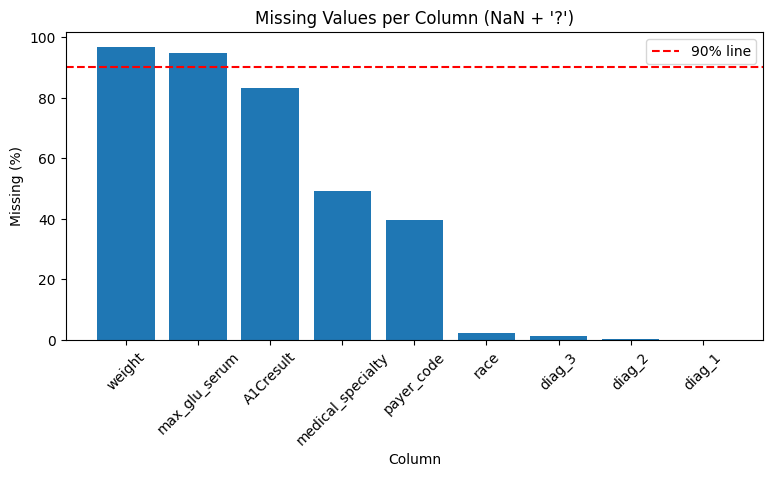

In [9]:
# bar chart of missing % per column
plt.figure(figsize=(9, 4))
plt.bar(missing_pct.index, missing_pct.values)
plt.axhline(90, color="red", linestyle="--", label="90% line")
plt.title("Missing Values per Column (NaN + '?')")
plt.xlabel("Column")
plt.ylabel("Missing (%)")
plt.xticks(rotation=45)
plt.legend()
plt.show()

In [10]:
# gender has its own placeholder value
df["gender"].value_counts()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

**What we see:**
- `weight` (96.86%) and `max_glu_serum` (94.75%) are above the 90% line.
- `A1Cresult` (83.28%), `medical_specialty` (49.08%) and `payer_code` (39.56%) are heavily missing too.
- `race` and the three diagnosis columns have only a small amount missing.
- `gender` has 3 rows marked `Unknown/Invalid`, another placeholder.

## Step 5: Summary Statistics

In [11]:
# numeric columns
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [12]:
# text columns: count, number of unique values, most common value and its frequency
df.describe(include="object")

,race,gender,age,weight,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,101766,101766,101766,101766,101766,101766,101766,101766,101766,5346,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,6,3,10,10,18,73,717,749,790,3,...,1,4,4,2,2,2,2,2,2,3
top,Caucasian,Female,[70-80),?,?,?,428,276,250,Norm,...,No,No,No,No,No,No,No,No,Yes,NO
freq,76099,54708,26068,98569,40256,49949,6862,6752,11555,2597,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864


**What to notice:**
- `encounter_id` and `patient_nbr` are IDs. Their mean and std mean nothing.
- `examide` and `citoglipton` have only **1 unique value**, so they carry no information.
- Count columns like `number_outpatient`, `number_emergency` and `number_inpatient` have a max far above the 75% value. That means a few extreme values (outliers), which we handle with IQR in step 3.

## Step 6: Encounters vs Patients

One patient can come to the hospital many times. If the same patient appears many times, the rows are not independent.

In [13]:
print("Rows (encounters):", len(df))
print("Unique encounter_id:", df["encounter_id"].nunique())
print("Unique patients:", df["patient_nbr"].nunique())
print("Fully duplicated rows:", df.duplicated().sum())

Rows (encounters): 101766
Unique encounter_id: 101766
Unique patients: 71518
Fully duplicated rows: 0


In [14]:
# how many encounters each patient has
visits_per_patient = df["patient_nbr"].value_counts()
visits_per_patient.describe()

count    71518.000000
mean         1.422942
std          1.090740
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
Name: count, dtype: float64

**What we see:** 101,766 encounters belong to only 71,518 patients, so many patients appear more than once. There are no fully duplicated rows. In the cleaning step we keep one encounter per patient.

## Step 7: Class Balance of `readmitted`

`readmitted` has 3 values: `NO`, `>30` (readmitted after 30 days) and `<30` (readmitted within 30 days).

Our question is about **early readmission**, so we compare `<30` against everything else.

In [15]:
# the 3 original classes
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [16]:
# same as percentage
(df["readmitted"].value_counts(normalize=True) * 100).round(2)

readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

In [17]:
# binary target: 1 = readmitted within 30 days, 0 = the rest (NO or >30)
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)

df["readmitted_30"].value_counts()

readmitted_30
0    90409
1    11357
Name: count, dtype: int64

In [18]:
# percentage of each class
(df["readmitted_30"].value_counts(normalize=True) * 100).round(2)

readmitted_30
0    88.84
1    11.16
Name: proportion, dtype: float64

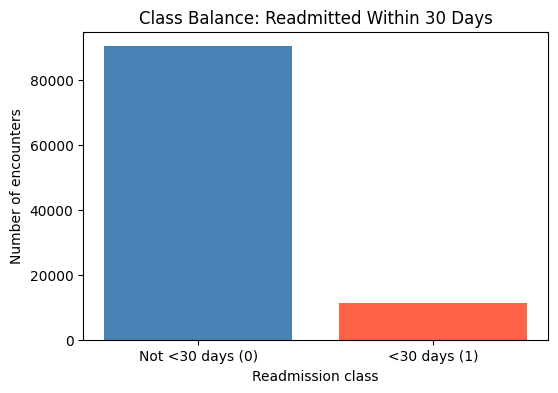

In [19]:
# bar chart of the binary target
counts = df["readmitted_30"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Not <30 days (0)", "<30 days (1)"], counts.values, color=["steelblue", "tomato"])
plt.title("Class Balance: Readmitted Within 30 Days")
plt.xlabel("Readmission class")
plt.ylabel("Number of encounters")
plt.show()

**What we see:** only 11,357 encounters (11.16%) were readmitted within 30 days, and 90,409 (88.84%) were not. The classes are **imbalanced** (about 1 to 8). A model could reach ~89% accuracy by always guessing "not readmitted", so in modeling we must handle the imbalance and look at recall and ROC-AUC, not only accuracy.

## Step 8: Look at the ID Mapping File

`IDS_mapping.csv` is not one table. It is **three lookup tables stacked on top of each other**, separated by blank lines:
`admission_type_id`, `discharge_disposition_id`, `admission_source_id`.

In [20]:
# read it as one table just to look at it
mapping = pd.read_csv("../data/IDS_mapping.csv")

print(mapping.shape)
mapping.head(12)

(67, 2)


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped
8,NaN,NaN
9,discharge_disposition_id,description


In [21]:
# rows where the first column is a header word show where each new table starts
mapping.loc[mapping["admission_type_id"].isin(["discharge_disposition_id", "admission_source_id"])]

,admission_type_id,description
9,discharge_disposition_id,description
41,admission_source_id,description


We will split this file into its three tables when we need the descriptions, for example to find the *Expired* and *Hospice* discharge codes in the cleaning step.

## Summary of Exploration

| Check | Result |
|-------|--------|
| Shape | 101,766 rows x 50 columns |
| Data types | 13 numeric, 37 text |
| `"?"` placeholders | 7 columns: `weight`, `medical_specialty`, `payer_code`, `race`, `diag_3`, `diag_2`, `diag_1` |
| Over 90% missing | `weight` (96.86%), `max_glu_serum` (94.75%, `None` = test not done) |
| Other placeholder | `gender` = `Unknown/Invalid` in 3 rows |
| Duplicated rows | 0 |
| Patients | 71,518 unique patients for 101,766 encounters |
| Target `<30` | 11,357 (11.16%) vs 90,409 (88.84%), imbalanced |

**Next notebook (02):** clean these problems.